### ***Atelier 2 : Réseaux de Neurones Convolutifs (CNNs)***

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import datasets, utils, models,layers
from tensorflow.keras.applications import VGG16, InceptionV3, ResNet50
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.optimizers import SGD
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight




### **Charger et normaliser CIFAR-10**

In [2]:
# Charger CIFAR-10
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normaliser entre 0 et 1
train_images = train_images.astype('float32') / 255.0
test_images = test_images.astype('float32') / 255.0

print("Train:", train_images.shape, train_labels.shape)
print("Test :", test_images.shape, test_labels.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1587s 9us/step
Train: (50000, 32, 32, 3) (50000, 1)
Test : (10000, 32, 32, 3) (10000, 1)


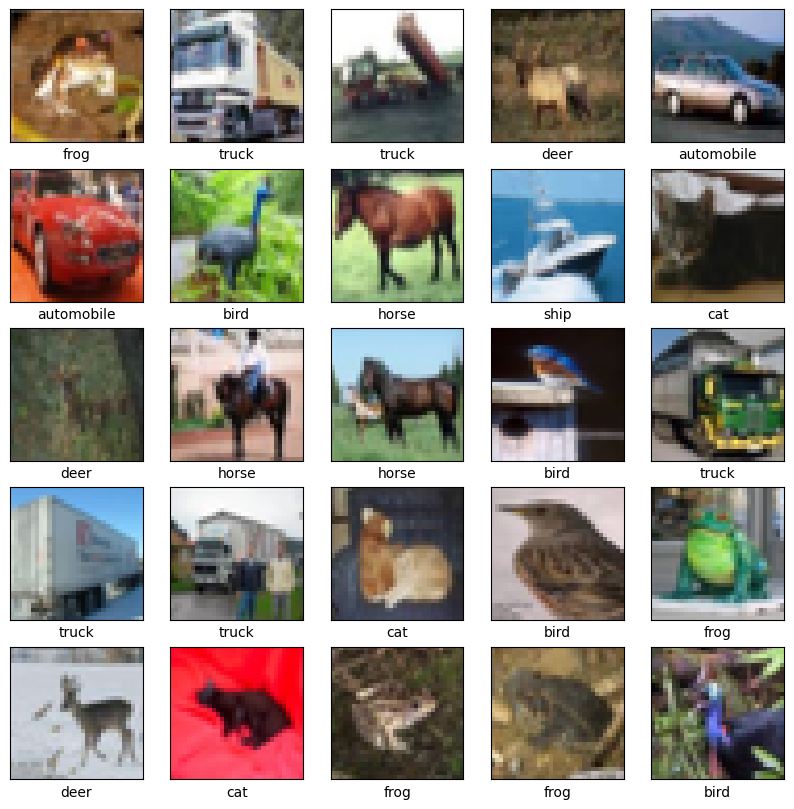

In [3]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer','dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i][0]])
plt.show()

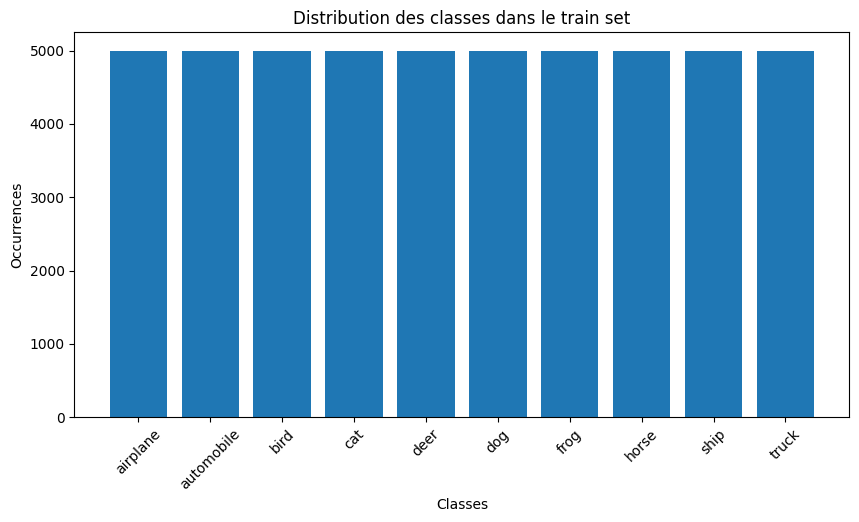

In [4]:

def plot_class_distribution(labels, class_names, title="Class Distribution"):
    labels = np.array(labels).flatten()

    # Compter occurrences
    counts = np.bincount(labels, minlength=len(class_names))

    # Affichage du graphique
    plt.figure(figsize=(10,5))
    plt.bar(class_names, counts)
    plt.title(title)
    plt.xlabel("Classes")
    plt.ylabel("Occurrences")
    plt.xticks(rotation=45)
    plt.show()

# Utilisation :
plot_class_distribution(train_labels, class_names, "Distribution des classes dans le train set")

In [5]:

def build_simple_cnn():
    model = models.Sequential([
        layers.Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3)),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(64, (3,3), activation='relu'),

        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    return model

model = build_simple_cnn()
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(train_images, train_labels,
                    epochs=10,
                    validation_data=(test_images, test_labels))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - accuracy: 0.4531 - loss: 1.5004 - val_accuracy: 0.5570 - val_loss: 1.2376
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6072 - loss: 1.1091 - val_accuracy: 0.6311 - val_loss: 1.0516
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6661 - loss: 0.9473 - val_accuracy: 0.6616 - val_loss: 0.9673
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7010 - loss: 0.8537 - val_accuracy: 0.6711 - val_loss: 0.9674
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7266 - loss: 0.7834 - val_accuracy: 0.6994 - val_loss: 0.8659
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7437 - loss: 0.7293 - val_accuracy: 0.7043 - val_loss: 0.8623
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7641 - loss: 0.6731 - val_accuracy: 0.7108 - val_loss: 0.8753
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7779 - loss: 0.6293 -

In [8]:
test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)
print(test_acc)

313/313 - 1s - 2ms/step - accuracy: 0.7089 - loss: 0.8819
0.708899974822998


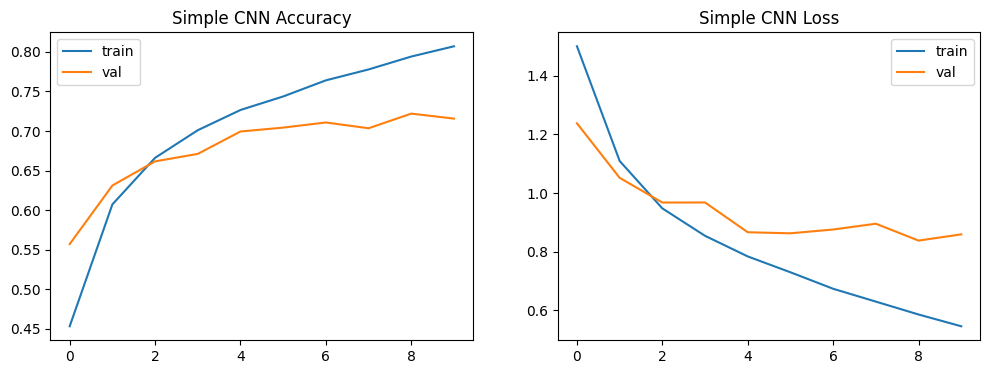

In [6]:

def plot_history(history, title="Model"):
    plt.figure(figsize=(12,4))

    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title(f'{title} Accuracy')
    plt.legend(['train','val'])

    plt.subplot(1,2,2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title(f'{title} Loss')
    plt.legend(['train','val'])
    plt.show()

plot_history(history, "Simple CNN")

***Question 2 : Redimensionner les images de l'ensemble de données CIFAR-10 à la nouvelle dimension de 224 × 224***

In [7]:

BATCH_SIZE = 32
TARGET_SIZE = (224, 224)

# Créer dataset train
train_dataset = tf.data.Dataset.from_tensor_slices((train_images, train_labels))
train_dataset = train_dataset.map(lambda x, y: (tf.image.resize(x, TARGET_SIZE), y))
train_dataset = train_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Créer dataset test
test_dataset = tf.data.Dataset.from_tensor_slices((test_images, test_labels))
test_dataset = test_dataset.map(lambda x, y: (tf.image.resize(x, TARGET_SIZE), y))
test_dataset = test_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [8]:
TARGET_SIZE_INC = (299, 299)

train_inc = tf.data.Dataset.from_tensor_slices((train_images, train_labels))
train_inc = train_inc.map(lambda x, y: (tf.image.resize(x, TARGET_SIZE_INC), y))
train_inc = train_inc.batch(32).prefetch(tf.data.AUTOTUNE)

test_inc = tf.data.Dataset.from_tensor_slices((test_images, test_labels))
test_inc = test_inc.map(lambda x, y: (tf.image.resize(x, TARGET_SIZE_INC), y))
test_inc = test_inc.batch(32).prefetch(tf.data.AUTOTUNE)

### Question3 :

### Question 3 : Entraînement From Scratch (VGG16, Inception, ResNet50)




*    **VGG16**





Epoch 1/10


E0000 00:00:1795176248.296600     153 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795176255.007369     153 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795176273.156002     153 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1562/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.1621 - loss: 2.2371

E0000 00:00:1795177076.664689     152 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795177079.459634     152 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795177094.863163     152 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 919s 560ms/step - accuracy: 0.2265 - loss: 2.1010 - val_accuracy: 0.3211 - val_loss: 1.8716
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 841s 538ms/step - accuracy: 0.4056 - loss: 1.6603 - val_accuracy: 0.4539 - val_loss: 1.5599
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 841s 538ms/step - accuracy: 0.5286 - loss: 1.3455 - val_accuracy: 0.5455 - val_loss: 1.2784
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 841s 538ms/step - accuracy: 0.6149 - loss: 1.1017 - val_accuracy: 0.5942 - val_loss: 1.1517
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 841s 538ms/step - accuracy: 0.6913 - loss: 0.8956 - val_accuracy: 0.5733 - val_loss: 1.3268
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 841s 538ms/step - accuracy: 0.7652 - loss: 0.6813 - val_accuracy: 0.6287 - val_loss: 1.2774
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 841s 538ms/step - accuracy: 0.8300 - loss: 0.4875 - val_accuracy: 0.6284 - val_loss: 1.5293
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 841s 538ms/step - accuracy: 0.8

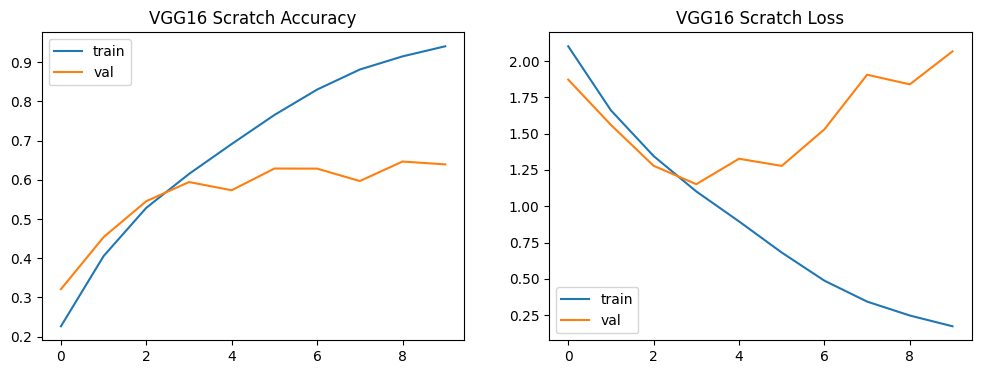

In [11]:

# Charger VGG16 sans les couches de classification originales

base_model = VGG16(
    weights=None,
    include_top=False,
    input_shape=(224, 224, 3)
)

# Ajouter notre propre classificateur

x = layers.Flatten()(base_model.output)
x = layers.Dense(256, activation='relu')(x)
output = layers.Dense(10, activation='softmax')(x)

# Construire le modèle final
model_vgg = models.Model(
    inputs=base_model.input,
    outputs=output
)

# Compilation
model_vgg.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Entraînement
history_vgg = model_vgg.fit(
    train_dataset,
    epochs=10,
    validation_data=test_dataset
)

# Visualisation
plot_history(history_vgg, "VGG16 Scratch")

313/313 ━━━━━━━━━━━━━━━━━━━━ 52s 163ms/step


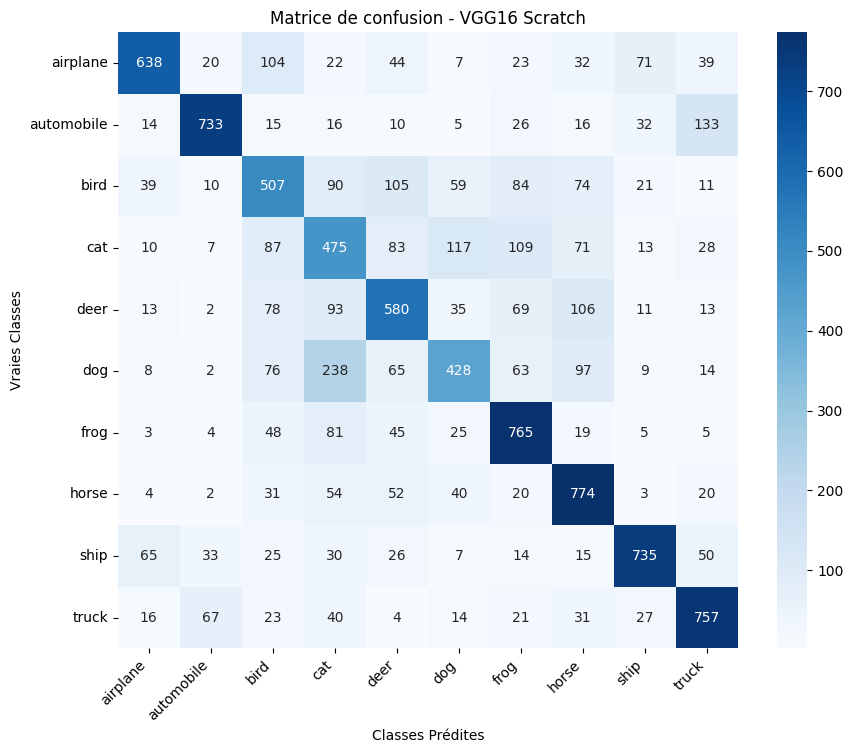

In [12]:

# 1. Extraire les vrais labels (y_true) à partir du test_dataset (une seule fois)
y_true = []
for images, labels in test_dataset:
    y_true.extend(labels.numpy())
y_true = np.array(y_true)

# 2. Obtenir les prédictions du modèle sur le jeu de test
y_pred_probs_vgg = model_vgg.predict(test_dataset)
y_pred_vgg = np.argmax(y_pred_probs_vgg, axis=1)

# 3. Calculer la matrice de confusion
cm = confusion_matrix(y_true, y_pred_vgg)

# 4. Afficher la matrice de confusion sous forme de heatmap avec les noms des classes
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=True,
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Matrice de confusion - VGG16 Scratch')
plt.xlabel('Classes Prédites')
plt.ylabel('Vraies Classes')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.show()

*    **RESNET 50**


In [6]:

# Charger Resnet sans les couches de classification originales

base_model = ResNet50(
    weights=None,
    include_top=False,
    input_shape=(224, 224, 3)
)

# Ajouter notre propre classificateur

x = layers.Flatten()(base_model.output)
x = layers.Dense(256, activation='relu')(x)
output = layers.Dense(10, activation='softmax')(x)

# Construire le modèle final
model_resnet = models.Model(
    inputs=base_model.input,
    outputs=output
)

# Compilation
model_resnet.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Entraînement
history_restnet = model_resnet.fit(
    train_dataset,
    epochs=10,
    validation_data=test_dataset
)



Epoch 1/10


I0000 00:00:1793554686.178944     143 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 529s 317ms/step - accuracy: 0.1996 - loss: 2.3277 - val_accuracy: 0.2628 - val_loss: 1.8606
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 486s 311ms/step - accuracy: 0.2700 - loss: 1.8303 - val_accuracy: 0.3265 - val_loss: 1.7618
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 487s 311ms/step - accuracy: 0.3541 - loss: 1.6351 - val_accuracy: 0.3525 - val_loss: 1.7110
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 486s 311ms/step - accuracy: 0.4094 - loss: 1.5004 - val_accuracy: 0.3960 - val_loss: 1.5715
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 487s 312ms/step - accuracy: 0.4528 - loss: 1.4020 - val_accuracy: 0.4362 - val_loss: 1.4660
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 486s 311ms/step - accuracy: 0.4933 - loss: 1.3106 - val_accuracy: 0.4719 - val_loss: 1.3944
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 487s 312ms/step - accuracy: 0.5088 - loss: 1.3010 - val_accuracy: 0.4906 - val_loss: 1.4131
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 487s 312ms/step - accuracy: 0.5

NameError: name 'plot_history' is not defined

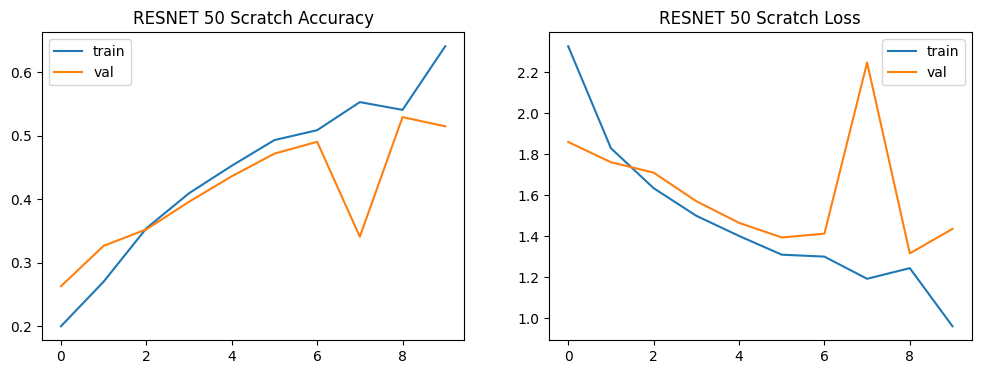

In [9]:
# Visualisation
plot_history(history_restnet, "RESNET 50 Scratch")

313/313 ━━━━━━━━━━━━━━━━━━━━ 34s 97ms/step


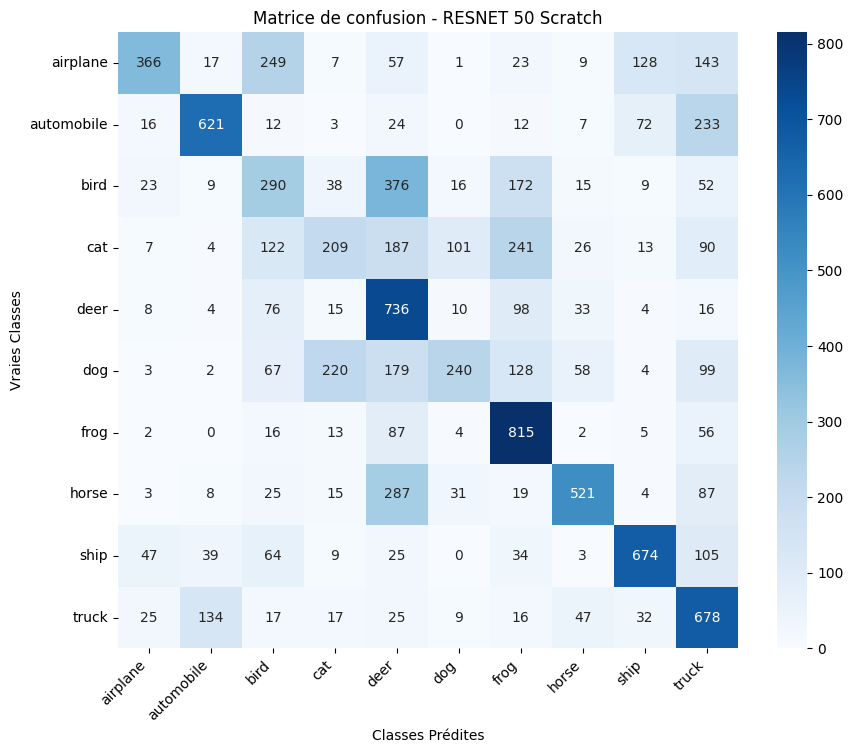

In [11]:

# 2. Obtenir les prédictions du modèle sur le jeu de test
y_pred_probs_resnet = model_resnet.predict(test_dataset)
y_pred_resnet = np.argmax(y_pred_probs_resnet, axis=1)

# 3. Calculer la matrice de confusion
cm = confusion_matrix(y_true, y_pred_resnet)

# 4. Afficher la matrice de confusion sous forme de heatmap avec les noms des classes
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=True,
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Matrice de confusion - RESNET 50 Scratch')
plt.xlabel('Classes Prédites')
plt.ylabel('Vraies Classes')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.show()

* **Inception**
 Le modèle InceptionV3 attend des images de taille :
- Hauteur (Height) : 299 pixels
- Largeur (Width) : 299 pixels
- Canaux (Channels) : 3 (RGB)

In [5]:

# Charger Resnet sans les couches de classification originales

base_model = InceptionV3(
    weights=None,
    include_top=False,
    input_shape=(299, 299, 3)
)

# Ajouter notre propre classificateur

x = layers.Flatten()(base_model.output)
x = layers.Dense(256, activation='relu')(x)
output = layers.Dense(10, activation='softmax')(x)

# Construire le modèle final
model_inception = models.Model(
    inputs=base_model.input,
    outputs=output
)

# Compilation
model_inception.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Entraînement
history_inception = model_inception.fit(
    train_inc,
    epochs=10,
    validation_data=test_inc
)



Epoch 1/10


E0000 00:00:1793725902.706851     182 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793725917.123207     182 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1562/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 464ms/step - accuracy: 0.1471 - loss: 2.4411

E0000 00:00:1793726678.842111     181 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793726689.959392     181 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 903s 529ms/step - accuracy: 0.2128 - loss: 2.0807 - val_accuracy: 0.2653 - val_loss: 2.0998
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 766s 490ms/step - accuracy: 0.4195 - loss: 1.5409 - val_accuracy: 0.4401 - val_loss: 1.5285
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 767s 491ms/step - accuracy: 0.5001 - loss: 1.3573 - val_accuracy: 0.5377 - val_loss: 1.2783
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 767s 491ms/step - accuracy: 0.5633 - loss: 1.1938 - val_accuracy: 0.5541 - val_loss: 1.2346
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 767s 491ms/step - accuracy: 0.6195 - loss: 1.0577 - val_accuracy: 0.6134 - val_loss: 1.1188
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 767s 491ms/step - accuracy: 0.6213 - loss: 1.0557 - val_accuracy: 0.5823 - val_loss: 1.1982
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 767s 491ms/step - accuracy: 0.6579 - loss: 0.9483 - val_accuracy: 0.6297 - val_loss: 1.0817
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 767s 491ms/step - accuracy: 0.7

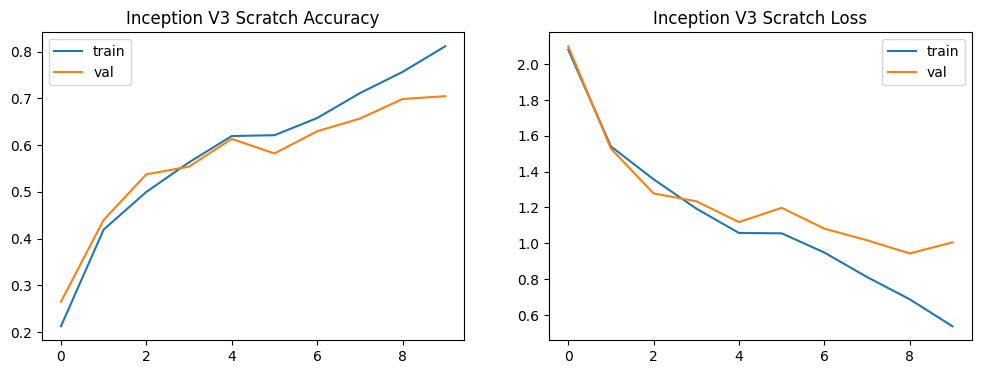

In [17]:
# Visualisation
plot_history(history_inception, "Inception V3 Scratch")

313/313 ━━━━━━━━━━━━━━━━━━━━ 42s 135ms/step


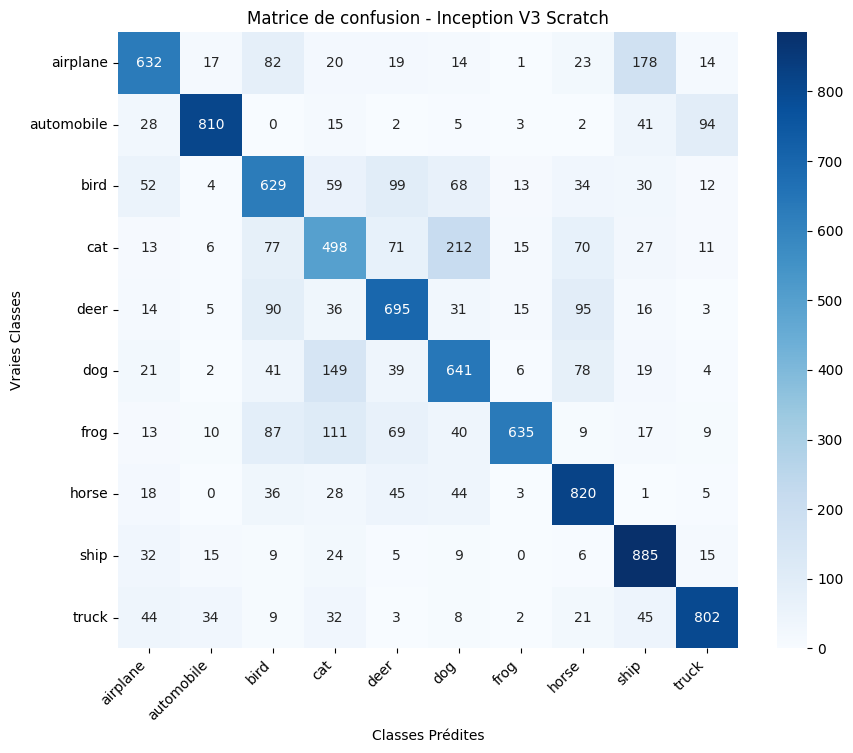

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer','dog', 'frog', 'horse', 'ship', 'truck']

# 1. Extraire les vrais labels (y_true) à partir du test_inc (une seule fois)
y_true = []
for images, labels in test_inc:
    y_true.extend(labels.numpy())
y_true = np.array(y_true)


# 2. Obtenir les prédictions du modèle sur le jeu de test
y_pred_probs_inc = model_inception.predict(test_inc)
y_pred_inc = np.argmax(y_pred_probs_inc, axis=1)

# 3. Calculer la matrice de confusion
cm = confusion_matrix(y_true, y_pred_inc)

# 4. Afficher la matrice de confusion sous forme de heatmap avec les noms des classes
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=True,
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Matrice de confusion - Inception V3 Scratch')
plt.xlabel('Classes Prédites')
plt.ylabel('Vraies Classes')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.show()


**Question5  . Ré-entraîner les modèles sur-mentionnés mais cette fois en utilisant la techniqued'apprentissage par transfert (Transfer learning) sur ensemble de données ImageNet.**


*    **VGG16**


In [9]:
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Ajouter notre propre classificateur

x = layers.Flatten()(base_model.output)
x = layers.Dense(256, activation='relu')(x)
output = layers.Dense(10, activation='softmax')(x)

# Construire le modèle final
model_vgg_tr = models.Model(
    inputs=base_model.input,
    outputs=output
)

# Compilation
model_vgg_tr.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Entraînement
history_vg_tr = model_vgg_tr.fit(
    train_dataset,
    epochs=10,
    validation_data=test_dataset
)

# Visualisation


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10


E0000 00:00:1795534761.663123     146 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795534764.598580     146 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795534770.189968     146 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1562/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 444ms/step - accuracy: 0.4098 - loss: 1.6646

E0000 00:00:1795535473.756405     146 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795535482.521103     146 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795535486.951780     146 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 806s 491ms/step - accuracy: 0.6061 - loss: 1.1130 - val_accuracy: 0.7744 - val_loss: 0.6539
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 740s 474ms/step - accuracy: 0.8688 - loss: 0.3817 - val_accuracy: 0.8642 - val_loss: 0.4015
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 740s 474ms/step - accuracy: 0.9287 - loss: 0.2108 - val_accuracy: 0.8714 - val_loss: 0.4162
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 741s 474ms/step - accuracy: 0.9591 - loss: 0.1198 - val_accuracy: 0.9030 - val_loss: 0.3545
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 741s 474ms/step - accuracy: 0.9728 - loss: 0.0803 - val_accuracy: 0.8995 - val_loss: 0.3612
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 741s 474ms/step - accuracy: 0.9820 - loss: 0.0542 - val_accuracy: 0.9064 - val_loss: 0.3593
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 741s 474ms/step - accuracy: 0.9864 - loss: 0.0419 - val_accuracy: 0.8976 - val_loss: 0.4266
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 741s 474ms/step - accuracy: 0.9

NameError: name 'history_vgg_tr' is not defined

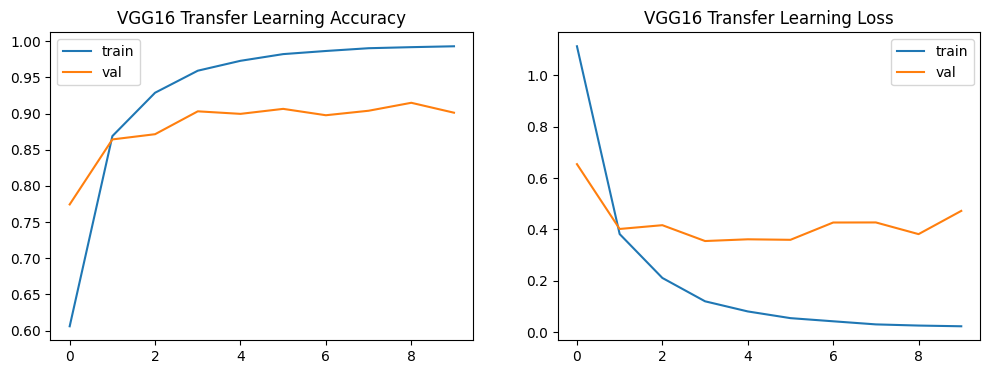

In [10]:
plot_history(history_vg_tr, "VGG16 Transfer Learning")

313/313 ━━━━━━━━━━━━━━━━━━━━ 44s 140ms/step


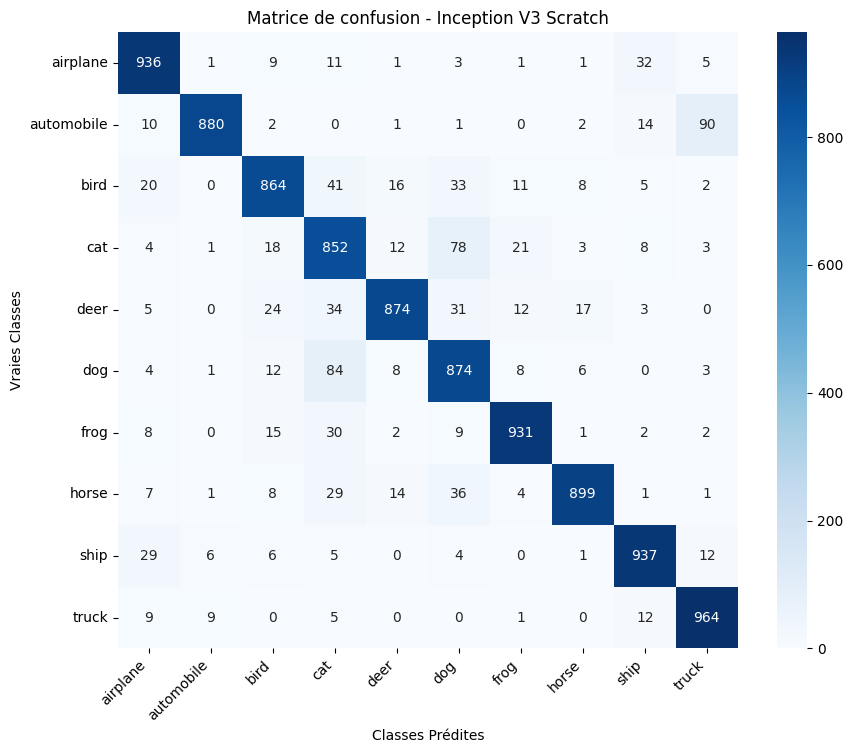

In [13]:
# 1. Extraire les vrais labels (y_true) à partir du test_dataset (une seule fois)
y_true = []
for images, labels in test_dataset:
    y_true.extend(labels.numpy())
y_true = np.array(y_true)
# 2. Obtenir les prédictions du modèle sur le jeu de test
y_pred_probs_vgg_tr = model_vgg_tr.predict(test_dataset)
y_pred_vgg_tr = np.argmax(y_pred_probs_vgg_tr, axis=1)

# 3. Calculer la matrice de confusion
cm = confusion_matrix(y_true, y_pred_vgg_tr)

# 4. Afficher la matrice de confusion sous forme de heatmap avec les noms des classes
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=True,
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Matrice de confusion - VGG16 Transfer Learning')
plt.xlabel('Classes Prédites')
plt.ylabel('Vraies Classes')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.show()




    

* ResNet 50

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 571s 342ms/step - accuracy: 0.8172 - loss: 0.6163 - val_accuracy: 0.9000 - val_loss: 0.2837
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 505s 323ms/step - accuracy: 0.9729 - loss: 0.0807 - val_accuracy: 0.9378 - val_loss: 0.2225
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 506s 324ms/step - accuracy: 0.9966 - loss: 0.0120 - val_accuracy: 0.9385 - val_loss: 0.2604
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 506s 324ms/step - accuracy: 0.9990 - loss: 0.0040 - val_accuracy: 0.9413 - val_loss: 0.2557
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 506s 324ms/step - accuracy: 0.9997 - loss: 0.0015 - val_accuracy: 0.9465 - val_loss: 0.2640
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 506s 324ms/step - accuracy: 1.0000 - loss: 1.8707e-04 - val_accuracy: 0.9470 - val_loss: 0.2739
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 507s 324ms/step - accuracy: 1.0000 - loss: 7.7196e-05 - val_accuracy: 0.9469 - val_loss: 0.2800
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 507s 324ms/s

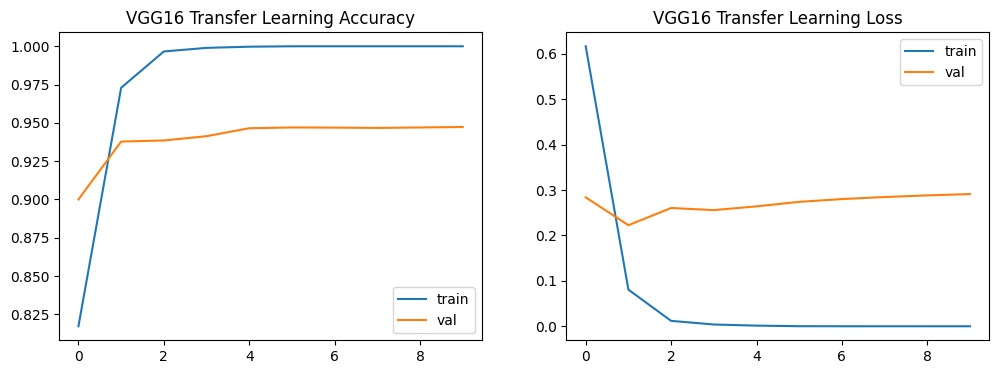

In [15]:
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Ajouter notre propre classificateur

x = layers.Flatten()(base_model.output)
x = layers.Dense(256, activation='relu')(x)
output = layers.Dense(10, activation='softmax')(x)

# Construire le modèle final
model_resnet_tr = models.Model(
    inputs=base_model.input,
    outputs=output
)

# Compilation
model_resnet_tr.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Entraînement
history_resnet_tr = model_resnet_tr.fit(
    train_dataset,
    epochs=10,
    validation_data=test_dataset
)

# Visualisation
plot_history(history_resnet_tr, "VGG16 Transfer Learning")

313/313 ━━━━━━━━━━━━━━━━━━━━ 38s 109ms/step


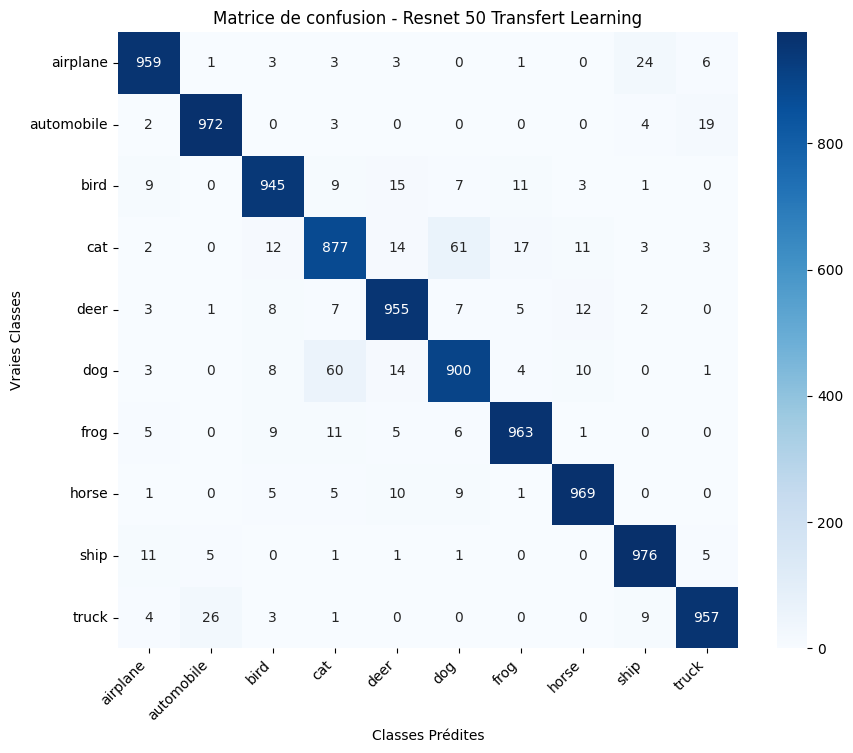

In [16]:
# 1. Extraire les vrais labels (y_true) à partir du test_dataset (une seule fois)
y_true = []
for images, labels in test_dataset:
    y_true.extend(labels.numpy())
y_true = np.array(y_true)
# 2. Obtenir les prédictions du modèle sur le jeu de test
y_pred_probs_resnet_tr = model_resnet_tr.predict(test_dataset)
y_pred_resnet_tr = np.argmax(y_pred_probs_resnet_tr, axis=1)

# 3. Calculer la matrice de confusion
cm = confusion_matrix(y_true, y_pred_resnet_tr)

# 4. Afficher la matrice de confusion sous forme de heatmap avec les noms des classes
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=True,
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Matrice de confusion - Resnet 50 Transfert Learning')
plt.xlabel('Classes Prédites')
plt.ylabel('Vraies Classes')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.show()




    

* Inception :

Epoch 1/10


E0000 00:00:1795555092.262272     144 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795555108.611851     144 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1562/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 433ms/step - accuracy: 0.7394 - loss: 0.9040

E0000 00:00:1795555814.843718     146 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795555827.638955     146 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 832s 492ms/step - accuracy: 0.8617 - loss: 0.4382 - val_accuracy: 0.9394 - val_loss: 0.1796
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 712s 456ms/step - accuracy: 0.9680 - loss: 0.0955 - val_accuracy: 0.9531 - val_loss: 0.1565
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 712s 455ms/step - accuracy: 0.9908 - loss: 0.0290 - val_accuracy: 0.9560 - val_loss: 0.1749
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 712s 455ms/step - accuracy: 0.9947 - loss: 0.0165 - val_accuracy: 0.9520 - val_loss: 0.1936
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 712s 456ms/step - accuracy: 0.9967 - loss: 0.0096 - val_accuracy: 0.9573 - val_loss: 0.1905
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 712s 455ms/step - accuracy: 0.9970 - loss: 0.0103 - val_accuracy: 0.9596 - val_loss: 0.1918
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 709s 454ms/step - accuracy: 0.9978 - loss: 0.0079 - val_accuracy: 0.9599 - val_loss: 0.1974
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 709s 454ms/step - accuracy: 0.9

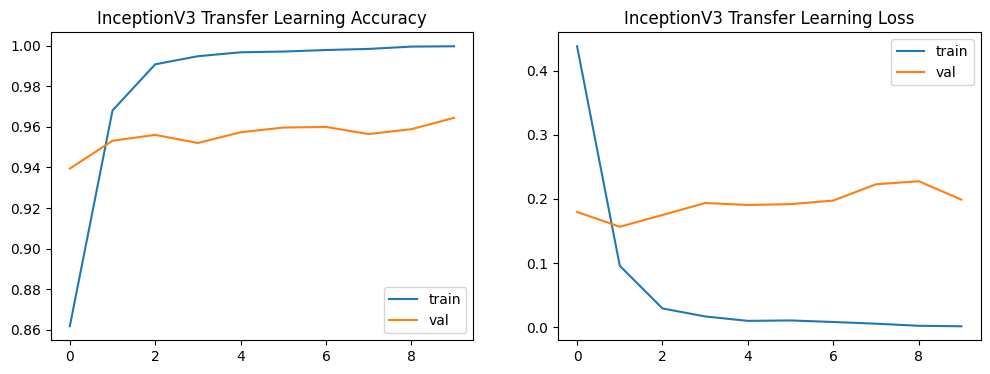

In [18]:
# Charger InceptionV3 pré-entraîné sur ImageNet
base_model = InceptionV3(
    weights='imagenet',
    include_top=False,
    input_shape=(299, 299, 3)
)

# Ajouter notre propre classificateur
x = layers.Flatten()(base_model.output)
x = layers.Dense(256, activation='relu')(x)
output = layers.Dense(10, activation='softmax')(x)

# Construire le modèle final
model_inception_tr = models.Model(
    inputs=base_model.input,
    outputs=output
)

# Compilation
model_inception_tr.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Entraînement
history_inception_tr = model_inception_tr.fit(
    train_inc,
    epochs=10,
    validation_data=test_inc
)

# Visualisation
plot_history(history_inception_tr, "InceptionV3 Transfer Learning")

313/313 ━━━━━━━━━━━━━━━━━━━━ 50s 142ms/step


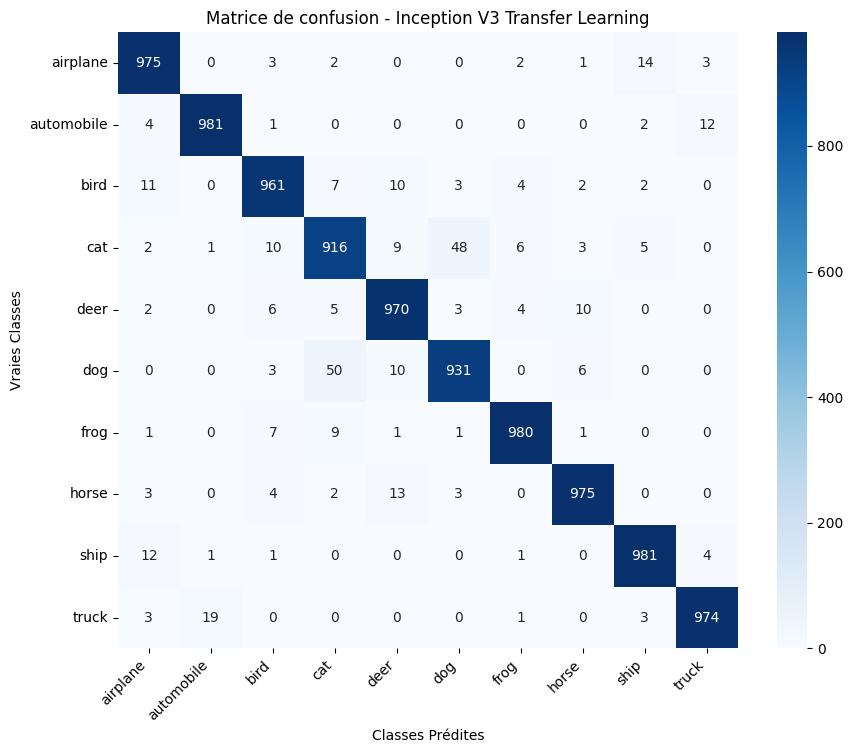

In [20]:
# 1. Extraire les vrais labels (y_true) à partir du test_dataset (une seule fois)
y_true = []
for images, labels in test_inc:
    y_true.extend(labels.numpy())
y_true = np.array(y_true)
# 2. Obtenir les prédictions du modèle sur le jeu de test
y_pred_probs_inception_tr = model_inception_tr.predict(test_inc)
y_pred_inception_tr = np.argmax(y_pred_probs_inception_tr, axis=1)

# 3. Calculer la matrice de confusion
cm = confusion_matrix(y_true, y_pred_inception_tr)

# 4. Afficher la matrice de confusion sous forme de heatmap avec les noms des classes
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=True,
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Matrice de confusion - Inception V3 Transfer Learning')
plt.xlabel('Classes Prédites')
plt.ylabel('Vraies Classes')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.show()




    